# Meta-Ensemble for Plant Disease Detection (MLP-Mixer + LSTM + SVM)

**Paper:** *A Lightweight Meta-Ensemble Approach for Plant Disease Detection Suitable for IoT-Based Environments*
**Authors:** Ritesh Maurya, Satyajit Mahapatra, Lucky Rajput
**Venue:** IEEE Access, 2024 — DOI: 10.1109/ACCESS.2024.3367443

---

## What this notebook reproduces

A **2-level stacking meta-ensemble** (NOT end-to-end):

```
LEVEL 1
  Branch A : MLP-Mixer  (raw 64x64x3 image -> softmax probabilities)
  Branch B : 4 frozen pretrained CNNs -> concat features (5632-d) -> LSTM -> softmax probs
LEVEL 2
  SVM (RBF)  : meta-features = concat[P_Mixer, P_LSTM]  ->  final class
```

**Stacking training order:** train Mixer -> extract CNN features -> train LSTM -> build
meta-features from Mixer & LSTM probs on the TRAIN set -> train SVM (GridSearchCV) ->
evaluate full pipeline on the TEST set.

### Dual experiment (workspace Rule 3)
| Scenario | Train transform | Val/Test transform |
|----------|-----------------|--------------------|
| **1 — Baseline** | Resize(64,64) + normalize [0,1] only | same (baseline) |
| **2 — Augmented** | Resize + Rotation + Zoom + HFlip + Brightness | baseline only |

### Confirmed reproduction choices
- **Framework:** TensorFlow / Keras (matches the original paper).
- **LR:** 1e-3 (Adam). **EarlyStopping**(patience=10, monitor=`val_accuracy`, restore_best_weights=True).
- **CNN feature extractors normalize:** pixel/255 -> [0,1] ONLY (no ImageNet mean/std).
- **Patch embedding:** resize 64->72, reshape into 9 patches of 24x24x3 (=1728), Dense(1728->128).
- **SVM:** GridSearchCV over C={0.1,1,2,10,100}, gamma={1,0.1,0.01,0.001,0.0001}, kernel={linear,rbf}.
- **Metrics:** Accuracy, F1-macro, Recall-macro, per-class classification_report (no ROC/AUC).


In [1]:
# Cell 2 — Install dependencies (most already present on Kaggle)
!pip install -q scikit-learn joblib openpyxl Pillow
print("Dependencies ready.")

Dependencies ready.


In [2]:
# Cell 3 — Imports
import os
import gc
import random
import numpy as np
import matplotlib.pyplot as plt
import joblib

import tensorflow as tf
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import (
    Dense, Dropout, Reshape, Add, LayerNormalization,
    GlobalAveragePooling1D, Permute, Resizing, LSTM,
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.applications import (
    MobileNet, DenseNet121, DenseNet169, DenseNet201,
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    classification_report, confusion_matrix,
)
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow version:", tf.__version__)

2026-06-20 04:45:49.856628: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781930750.130827      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781930750.208913      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781930750.817465      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781930750.817526      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781930750.817528      58 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0


In [3]:
# Cell 4 — Reproducibility seeds (workspace Rule 7)
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Seeds fixed at {SEED}")

Seeds fixed at 42


In [4]:
# Cell 5 — GPU setup (single device)
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("memory_growth warning:", e)
print(f"Physical GPUs detected: {len(gpus)}")
print("Running in single-device mode (no MirroredStrategy).")

Physical GPUs detected: 2
Running in single-device mode (no MirroredStrategy).


In [5]:
# Cell 6 — Configuration
DATA_DIR   = "/kaggle/input/datasets/tminhhi/native-ot/dataset_smartcrop_plit_300"
WORK_DIR   = "/kaggle/working"

IMG_SIZE   = 64          # input image side (64x64x3)
BATCH_SIZE = 512         # paper Table 5/6
LR         = 1e-3        # confirmed
EPOCHS     = 100         # EarlyStopping will stop earlier
PATIENCE   = 10          # EarlyStopping patience

# MLP-Mixer hyperparameters (paper Table 5 / Table 7)
N_PATCHES  = 9           # 3x3 grid of patches
PATCH_SIDE = 24          # 72 / 3  -> each patch is 24x24x3 = 1728
PATCH_DIM  = PATCH_SIDE * PATCH_SIDE * 3   # 1728
RESIZE_FOR_PATCH = 72    # compress 64 -> 72 before patching
D          = 128         # embedding dim
N_LAYERS   = 7           # number of mixer blocks
DROPOUT    = 0.25

# LSTM branch
LSTM_UNITS = 30          # paper Table 6
# CNN feature dims:  MobileNet 1024 + DenseNet121 1024 + DenseNet169 1664 + DenseNet201 1920
FEATURE_DIM = None       # auto-detected after first extraction

# GLOBAL batch size scaling for multi-GPU (Rule 14)
GLOBAL_BATCH_SIZE = BATCH_SIZE  # DataParallel-style auto-split handled by Keras

print("Config loaded.")
print(f"  DATA_DIR = {DATA_DIR}")
print(f"  IMG_SIZE={IMG_SIZE} BATCH={BATCH_SIZE} LR={LR} EPOCHS={EPOCHS}")
print(f"  Mixer: N={N_PATCHES} D={D} layers={N_LAYERS} dropout={DROPOUT}")
print(f"  LSTM units={LSTM_UNITS}")

Config loaded.
  DATA_DIR = /kaggle/input/datasets/tminhhi/native-ot/dataset_smartcrop_plit_300
  IMG_SIZE=64 BATCH=512 LR=0.001 EPOCHS=100
  Mixer: N=9 D=128 layers=7 dropout=0.25
  LSTM units=30


In [6]:
# Cell 7 — Load dataset from pre-split train/val/test folders (Rule 12)
# Dataset already split by user: DATA_DIR/train/, DATA_DIR/val/, DATA_DIR/test/

def load_split(split_dir, img_size=IMG_SIZE):
    class_names = sorted(
        d for d in os.listdir(split_dir)
        if os.path.isdir(os.path.join(split_dir, d))
    )
    class_to_idx = {c: i for i, c in enumerate(class_names)}
    X, y = [], []
    for cname in class_names:
        cdir = os.path.join(split_dir, cname)
        for fn in os.listdir(cdir):
            fp = os.path.join(cdir, fn)
            try:
                img = tf.keras.utils.load_img(fp, target_size=(img_size, img_size))
            except Exception:
                continue
            arr = tf.keras.utils.img_to_array(img) / 255.0  # normalize [0,1]
            X.append(arr)
            y.append(class_to_idx[cname])
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.int64), class_names

TRAIN_DIR = os.path.join(DATA_DIR, 'train')
VAL_DIR   = os.path.join(DATA_DIR, 'val')
TEST_DIR  = os.path.join(DATA_DIR, 'test')

X_train, y_train, class_names = load_split(TRAIN_DIR)
X_val,   y_val,   _           = load_split(VAL_DIR)
X_test,  y_test,  _           = load_split(TEST_DIR)

num_classes = len(class_names)

print(f'Detected {num_classes} classes: {class_names}')
print(f'Train : {X_train.shape} | Val : {X_val.shape} | Test : {X_test.shape}')
print(f'Pixel range: [{X_train.min():.3f}, {X_train.max():.3f}]')


Detected 5 classes: ['anthracnose', 'healthy', 'leaf_curl', 'leaf_spot', 'nutrient_deficiency']
Train : (1597, 64, 64, 3) | Val : (491, 64, 64, 3) | Test : (373, 64, 64, 3)
Pixel range: [0.000, 0.961]


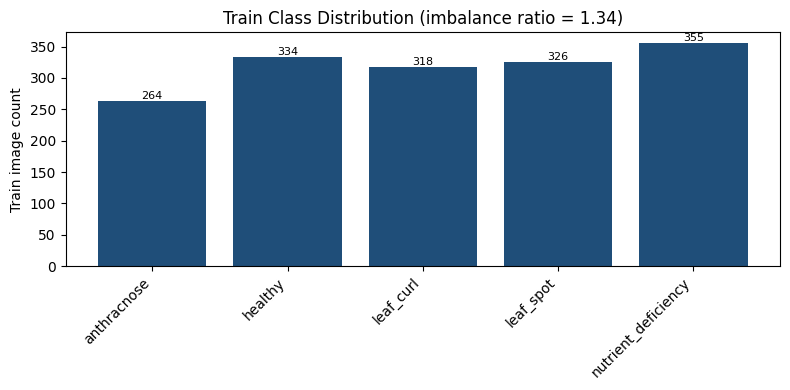

Imbalance ratio 1.34 < 1.5 -> no class weighting


In [7]:
# Cell 8 — Dataset Distribution + auto class-imbalance handling (Rule 11)
counts = np.bincount(y_train, minlength=num_classes)
imbalance_ratio = counts.max() / max(counts.min(), 1)

plt.figure(figsize=(max(8, num_classes * 0.6), 4))
bars = plt.bar(range(num_classes), counts, color="#1f4e79")
plt.xticks(range(num_classes), class_names, rotation=45, ha="right")
plt.ylabel("Train image count")
plt.title(f"Train Class Distribution (imbalance ratio = {imbalance_ratio:.2f})")
for b, c in zip(bars, counts):
    plt.text(b.get_x() + b.get_width() / 2, c, str(c), ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, "dataset_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

USE_CLASS_WEIGHT = imbalance_ratio >= 1.5
if USE_CLASS_WEIGHT:
    cw = compute_class_weight("balanced", classes=np.arange(num_classes), y=y_train)
    class_weight_dict = {i: float(w) for i, w in enumerate(cw)}
    print(f"Imbalance ratio {imbalance_ratio:.2f} >= 1.5 -> USING class weighting")
    print("class_weight =", class_weight_dict)
else:
    class_weight_dict = None
    print(f"Imbalance ratio {imbalance_ratio:.2f} < 1.5 -> no class weighting")

# SVM class_weight (Level 2)
SVM_CLASS_WEIGHT = "balanced" if USE_CLASS_WEIGHT else None

## Shared model builders & evaluation helpers

The MLP-Mixer and LSTM architectures are identical across both scenarios, so we
define them once. Each scenario re-instantiates **fresh** model weights.

In [8]:
# Cell 9 — Model builders (Mixer, LSTM) + helpers

def build_mixer(num_classes, n_patches=N_PATCHES, d=D,
                num_layers=N_LAYERS, dropout_rate=DROPOUT):
    """MLP-Mixer matching paper Table 7.
    64x64x3 -> resize 72x72 -> reshape 9 patches of 24*24*3=1728 -> Dense(d).
    Uses Resizing + Permute instead of Lambda for Keras 3 serialization safety."""
    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # Patch embedding
    x = Resizing(RESIZE_FOR_PATCH, RESIZE_FOR_PATCH, name="resize_72")(inputs)  # (B,72,72,3)
    x = Reshape((n_patches, PATCH_DIM), name="patchify")(x)                      # (B,9,1728)
    x = Dense(d, name="patch_proj")(x)                                            # (B,9,128)
    x = Dropout(dropout_rate)(x)

    for i in range(num_layers):
        # --- Token mixing ---
        y = Dense(d, activation="gelu", name=f"tok_fc1_{i}")(x)   # (B,9,128)
        y = Permute((2, 1), name=f"tok_T1_{i}")(y)                 # (B,128,9)
        y = Dense(n_patches, name=f"tok_fc2_{i}")(y)               # (B,128,9)
        y = Permute((2, 1), name=f"tok_T2_{i}")(y)                 # (B,9,128)
        x = Add(name=f"tok_add_{i}")([x, y])
        x = LayerNormalization(name=f"tok_ln_{i}")(x)

        # --- Channel mixing ---
        y = Dense(d, activation="gelu", name=f"ch_fc1_{i}")(x)    # (B,9,128)
        y = Dense(d, name=f"ch_fc2_{i}")(y)                        # (B,9,128)
        x = Add(name=f"ch_add_{i}")([x, y])
        x = LayerNormalization(name=f"ch_ln_{i}")(x)

    x = Dropout(dropout_rate)(x)
    x = GlobalAveragePooling1D(name="gap")(x)                      # (B,128)
    outputs = Dense(num_classes, activation="softmax", name="mixer_out")(x)
    return Model(inputs, outputs, name="MLP_Mixer")


def build_lstm(num_classes, feature_dim, lstm_units=LSTM_UNITS):
    """LSTM over cached CNN features. Input shape: (timestep=1, feature_dim)."""
    inputs = Input(shape=(1, feature_dim))
    x = LSTM(lstm_units, name="lstm")(inputs)
    outputs = Dense(num_classes, activation="softmax", name="lstm_out")(x)
    return Model(inputs, outputs, name="LSTM_branch")


def plot_learning_curve(history, title, out_path):
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["loss"], label="train loss")
    if "val_loss" in h:
        ax[0].plot(h["val_loss"], label="val loss")
    ax[0].set_title(f"{title} — Loss"); ax[0].set_xlabel("epoch")
    ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].grid(alpha=0.3)

    acc_key = "accuracy" if "accuracy" in h else "acc"
    val_acc_key = "val_accuracy" if "val_accuracy" in h else "val_acc"
    ax[1].plot(h[acc_key], label="train acc")
    if val_acc_key in h:
        ax[1].plot(h[val_acc_key], label="val acc")
    ax[1].set_title(f"{title} — Accuracy"); ax[1].set_xlabel("epoch")
    ax[1].set_ylabel("accuracy"); ax[1].legend(); ax[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()


def plot_confusion_matrix(y_true, y_pred, names, title, out_path):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(names)))
    fig, ax = plt.subplots(figsize=(max(6, len(names) * 0.7),
                                    max(5, len(names) * 0.6)))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
    ax.set_xticklabels(names, rotation=45, ha="right")
    ax.set_yticklabels(names)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    thresh = cm.max() / 2.0 if cm.max() > 0 else 0.5
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()


def report_metrics(y_true, y_pred, names, tag):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"=== {tag} ===")
    print(f"Accuracy      : {acc:.4f}")
    print(f"F1-score(macro): {f1:.4f}")
    print(f"Recall(macro) : {rec:.4f}\n")
    print(classification_report(y_true, y_pred, target_names=names,
                                digits=4, zero_division=0))
    return {"accuracy": acc, "f1_macro": f1, "recall_macro": rec}

print("Builders & helpers defined.")

Builders & helpers defined.


In [9]:
# Cell — tf.data helper
def make_tf_dataset(X, y, batch_size, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED)
    ds = ds.batch(batch_size, drop_remainder=False)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

print("make_tf_dataset helper ready.")

make_tf_dataset helper ready.


In [10]:
# Cell 10 — CNN feature extractors (4 frozen ImageNet CNNs, built ONCE)
# Normalize: images already in [0,1] (confirmed: NO ImageNet mean/std).

def build_feature_extractors():
    common = dict(include_top=False, pooling="avg",
                  input_shape=(IMG_SIZE, IMG_SIZE, 3), weights="imagenet")
    nets = {
        "MobileNet":   MobileNet(**common),
        "DenseNet121": DenseNet121(**common),
        "DenseNet169": DenseNet169(**common),
        "DenseNet201": DenseNet201(**common),
    }
    for m in nets.values():
        m.trainable = False
    return nets

_feature_nets = build_feature_extractors()
for name, m in _feature_nets.items():
    print(f"{name:12s} -> feature dim {m.output_shape[-1]}")


def extract_cnn_features(images, batch_size=64):
    '''images: (N,64,64,3) in [0,1]. Returns (N, 5632) concat features.'''
    feats = [m.predict(images, batch_size=batch_size, verbose=0)
             for m in _feature_nets.values()]
    return np.concatenate(feats, axis=1)

print("Feature extractors ready.")

/tmp/ipykernel_58/2158581383.py:8: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  "MobileNet":   MobileNet(**common),
I0000 00:00:1781930781.125097      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1781930781.130927      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
51877672/51877672 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNet    -> feature dim 1024
DenseNet121  -> feature dim 1024
DenseNet169  -> feature dim 1664
DenseNet201  -> feature dim 1920
Feature extractors ready.


# Scenario 1 — Baseline (No Augmentation)

Training transform = Resize(64,64) + normalize [0,1] only. Full stacking pipeline:
Mixer -> CNN features -> LSTM -> meta-features -> SVM -> evaluation.

In [11]:
# Cell — Scenario 1 training data (BASELINE: no augmentation)
# Baseline train transform = resize(64)+[0,1] which is already how X_train is stored.
X_train_s1 = X_train.copy()
y_train_s1 = y_train.copy()
print("Scenario 1 train set:", X_train_s1.shape)

Scenario 1 train set: (1597, 64, 64, 3)


In [12]:
# Cell — Scenario 1 class weights (recomputed for this train set)
_counts_s1 = np.bincount(y_train_s1, minlength=num_classes)
_ratio_s1 = _counts_s1.max() / max(_counts_s1.min(), 1)
if _ratio_s1 >= 1.5:
    _cw_s1 = compute_class_weight("balanced", classes=np.arange(num_classes), y=y_train_s1)
    class_weight_s1 = {i: float(w) for i, w in enumerate(_cw_s1)}
    print("Scenario 1: class weighting ON ->", class_weight_s1)
else:
    class_weight_s1 = None
    print("Scenario 1: class weighting OFF (ratio {:.2f})".format(_ratio_s1))

Scenario 1: class weighting OFF (ratio 1.34)


In [13]:
# Cell — Scenario 1: build MLP-Mixer + print summary (Rule 5)
mixer_s1 = build_mixer(num_classes)
mixer_s1.compile(
    optimizer=Adam(LR, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
mixer_s1.summary()
mixer_params_s1 = mixer_s1.count_params()
print(f"MLP-Mixer S1 params: {mixer_params_s1:,}")

Model: "MLP_Mixer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resize_72           │ (None, 72, 72, 3) │          0 │ input_layer_4[0]… │
│ (Resizing)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patchify (Reshape)  │ (None, 9, 1728)   │          0 │ resize_72[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_proj (Dense)  │ (None, 9, 128)    │    221,312 │ patchify[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 9, 128)    │          0 │ patch_proj[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_fc1_0 (Dense)   │ (None, 9, 128)    │     16,512 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_T1_0 (Permute)  │ (None, 128, 9)    │          0 │ tok_fc1_0[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_fc2_0 (Dense)   │ (None, 128, 9)    │         90 │ tok_T1_0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_T2_0 (Permute)  │ (None, 9, 128)    │          0 │ tok_fc2_0[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_add_0 (Add)     │ (None, 9, 128)    │          0 │ dropout[0][0],    │
│                     │                   │            │ tok_T2_0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_ln_0            │ (None, 9, 128)    │        256 │ tok_add_0[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ch_fc1_0 (Dense)    │ (None, 9, 128)    │     16,512 │ tok_ln_0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ch_fc2_0 (Dense)    │ (None, 9, 128)    │     16,512 │ ch_fc1_0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ch_add_0 (Add)      │ (None, 9, 128)    │          0 │ tok_ln_0[0][0],   │
│                     │                   │            │ ch_fc2_0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ch_ln_0             │ (None, 9, 128)    │        256 │ ch_add_0[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_fc1_1 (Dense)   │ (None, 9, 128)    │     16,512 │ ch_ln_0[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_T1_1 (Permute)  │ (None, 128, 9)    │          0 │ tok_fc1_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_fc2_1 (Dense)   │ (None, 128, 9)    │         90 │ tok_T1_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_T2_1 (Permute)  │ (None, 9, 128)    │          0 │ tok_fc2_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_add_1 (Add)     │ (None, 9, 128)    │          0 │ ch_ln_0[0][0],    │
│                     │                   │            │ tok_T2_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_ln_1            │ (None, 9, 128)    │        256 │ tok_add_1[0][0]   │
│ (LayerNormalizatio… │                   │            │                 

 Total params: 572,923 (2.19 MB)

 Trainable params: 572,923 (2.19 MB)

 Non-trainable params: 0 (0.00 B)

MLP-Mixer S1 params: 572,923


In [14]:
# Cell — Scenario 1: train MLP-Mixer
ckpt_mixer_s1 = os.path.join(WORK_DIR, "best_mixer_s1.keras")
cb_mixer_s1 = [
    ModelCheckpoint(ckpt_mixer_s1, monitor="val_accuracy",
                    save_best_only=True, mode="max"),
    EarlyStopping(monitor="val_accuracy", patience=PATIENCE,
                  restore_best_weights=True, mode="max"),
    tf.keras.callbacks.TerminateOnNaN(),
]
train_ds_mixer_s1 = make_tf_dataset(X_train_s1, y_train_s1, BATCH_SIZE, shuffle=True)
val_ds_mixer      = make_tf_dataset(X_val, y_val, BATCH_SIZE)
hist_mixer_s1 = mixer_s1.fit(
    train_ds_mixer_s1,
    validation_data=val_ds_mixer,
    epochs=EPOCHS,
    class_weight=class_weight_s1,
    callbacks=cb_mixer_s1, verbose=2,
)
print("Mixer S1 training done.")

Epoch 1/100


I0000 00:00:1781930809.138505     137 service.cc:152] XLA service 0x7d9ed0002840 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781930809.138574     137 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1781930809.138582     137 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1781930812.859999     137 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1781930820.158784     137 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


4/4 - 37s - 9s/step - accuracy: 0.2260 - loss: 2.1869 - val_accuracy: 0.1650 - val_loss: 1.7434
Epoch 2/100
4/4 - 0s - 119ms/step - accuracy: 0.1866 - loss: 1.7124 - val_accuracy: 0.2077 - val_loss: 1.7020
Epoch 3/100
4/4 - 0s - 40ms/step - accuracy: 0.2292 - loss: 1.6839 - val_accuracy: 0.1996 - val_loss: 1.6447
Epoch 4/100
4/4 - 0s - 113ms/step - accuracy: 0.2123 - loss: 1.6915 - val_accuracy: 0.2098 - val_loss: 1.5984
Epoch 5/100
4/4 - 0s - 36ms/step - accuracy: 0.2123 - loss: 1.6229 - val_accuracy: 0.2077 - val_loss: 1.6276
Epoch 6/100
4/4 - 0s - 114ms/step - accuracy: 0.2461 - loss: 1.6313 - val_accuracy: 0.3483 - val_loss: 1.5137
Epoch 7/100
4/4 - 0s - 33ms/step - accuracy: 0.2793 - loss: 1.5388 - val_accuracy: 0.3401 - val_loss: 1.4586
Epoch 8/100
4/4 - 0s - 34ms/step - accuracy: 0.3150 - loss: 1.4850 - val_accuracy: 0.3422 - val_loss: 1.4388
Epoch 9/100
4/4 - 0s - 113ms/step - accuracy: 0.3456 - loss: 1.4275 - val_accuracy: 0.3503 - val_loss: 1.3401
Epoch 10/100
4/4 - 0s - 114m

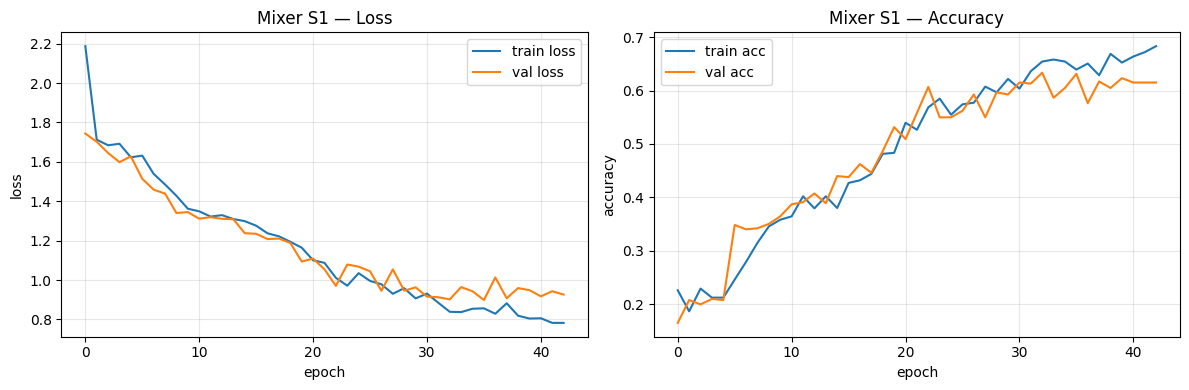

In [15]:
# Cell — Scenario 1: MLP-Mixer learning curve (Rule 6)
MIXER_LC_S1 = os.path.join(WORK_DIR, "mixer_s1_learning_curve.png")
plot_learning_curve(hist_mixer_s1, "Mixer S1", MIXER_LC_S1)

In [16]:
# Cell — Scenario 1: reload best Mixer + get probabilities (Rule 10)
best_mixer_s1 = tf.keras.models.load_model(ckpt_mixer_s1)
mixer_probs_train_s1 = best_mixer_s1.predict(X_train_s1, batch_size=BATCH_SIZE, verbose=0)
mixer_probs_test_s1  = best_mixer_s1.predict(X_test,        batch_size=BATCH_SIZE, verbose=0)
print("Mixer probs:", mixer_probs_train_s1.shape, mixer_probs_test_s1.shape)

Mixer probs: (1597, 5) (373, 5)


In [17]:
# Cell — Scenario 1: extract CNN features (train uses baseline images)
feat_train_s1 = extract_cnn_features(X_train_s1)
feat_test_s1  = extract_cnn_features(X_test)
FEATURE_DIM = feat_train_s1.shape[1]   # auto-detect (expected 5632)
print("CNN features:", feat_train_s1.shape, feat_test_s1.shape, "| FEATURE_DIM =", FEATURE_DIM)

# reshape for LSTM: (N, timestep=1, FEATURE_DIM)
feat_train_s1_lstm = feat_train_s1.reshape(-1, 1, FEATURE_DIM)
feat_test_s1_lstm  = feat_test_s1.reshape(-1, 1, FEATURE_DIM)

# Extract val CNN features ONCE (same across both scenarios)
feat_val = extract_cnn_features(X_val)
feat_val_lstm = feat_val.reshape(-1, 1, FEATURE_DIM)
print('Val CNN features:', feat_val_lstm.shape)


2026-06-20 04:47:40.033348: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-20 04:47:40.171735: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-20 04:47:48.305848: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-20 04:47:48.444831: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-20 04:49:47.003137: E external/local_xla/xla/stream_

CNN features: (1597, 5632) (373, 5632) | FEATURE_DIM = 5632


2026-06-20 04:50:33.201340: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-20 04:50:33.351809: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-20 04:50:33.489658: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


Val CNN features: (491, 1, 5632)


In [18]:
# Cell — Scenario 1: build LSTM + print summary (Rule 5)
lstm_s1 = build_lstm(num_classes, FEATURE_DIM)
lstm_s1.compile(
    optimizer=Adam(LR, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
lstm_s1.summary()
lstm_params_s1 = lstm_s1.count_params()
print(f"LSTM S1 params: {lstm_params_s1:,}")

Model: "LSTM_branch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 1, 5632)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30)             │       679,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_out (Dense)                │ (None, 5)              │           155 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 679,715 (2.59 MB)

 Trainable params: 679,715 (2.59 MB)

 Non-trainable params: 0 (0.00 B)

LSTM S1 params: 679,715


In [19]:
# Cell — Scenario 1: train LSTM on cached features
ckpt_lstm_s1 = os.path.join(WORK_DIR, "best_lstm_s1.keras")
cb_lstm_s1 = [
    ModelCheckpoint(ckpt_lstm_s1, monitor="val_accuracy",
                    save_best_only=True, mode="max"),
    EarlyStopping(monitor="val_accuracy", patience=PATIENCE,
                  restore_best_weights=True, mode="max"),
    tf.keras.callbacks.TerminateOnNaN(),
]
train_ds_lstm_s1 = make_tf_dataset(feat_train_s1_lstm, y_train_s1, BATCH_SIZE, shuffle=True)
val_ds_lstm      = make_tf_dataset(feat_val_lstm, y_val, BATCH_SIZE)
hist_lstm_s1 = lstm_s1.fit(
    train_ds_lstm_s1,
    validation_data=val_ds_lstm,
    epochs=EPOCHS,
    class_weight=class_weight_s1,
    callbacks=cb_lstm_s1, verbose=2,
)
print("LSTM S1 training done.")

Epoch 1/100
4/4 - 3s - 862ms/step - accuracy: 0.3751 - loss: 1.4364 - val_accuracy: 0.5947 - val_loss: 1.0853
Epoch 2/100
4/4 - 0s - 32ms/step - accuracy: 0.6744 - loss: 0.9570 - val_accuracy: 0.7434 - val_loss: 0.8145
Epoch 3/100
4/4 - 0s - 28ms/step - accuracy: 0.7840 - loss: 0.7039 - val_accuracy: 0.7719 - val_loss: 0.6823
Epoch 4/100
4/4 - 0s - 30ms/step - accuracy: 0.8341 - loss: 0.5629 - val_accuracy: 0.7943 - val_loss: 0.5890
Epoch 5/100
4/4 - 0s - 28ms/step - accuracy: 0.8585 - loss: 0.4765 - val_accuracy: 0.8310 - val_loss: 0.5474
Epoch 6/100
4/4 - 0s - 15ms/step - accuracy: 0.8961 - loss: 0.3999 - val_accuracy: 0.8167 - val_loss: 0.5043
Epoch 7/100
4/4 - 0s - 25ms/step - accuracy: 0.8998 - loss: 0.3570 - val_accuracy: 0.8411 - val_loss: 0.4673
Epoch 8/100
4/4 - 0s - 14ms/step - accuracy: 0.9198 - loss: 0.3204 - val_accuracy: 0.8289 - val_loss: 0.4642
Epoch 9/100
4/4 - 0s - 26ms/step - accuracy: 0.9224 - loss: 0.2851 - val_accuracy: 0.8493 - val_loss: 0.4446
Epoch 10/100
4/4 -

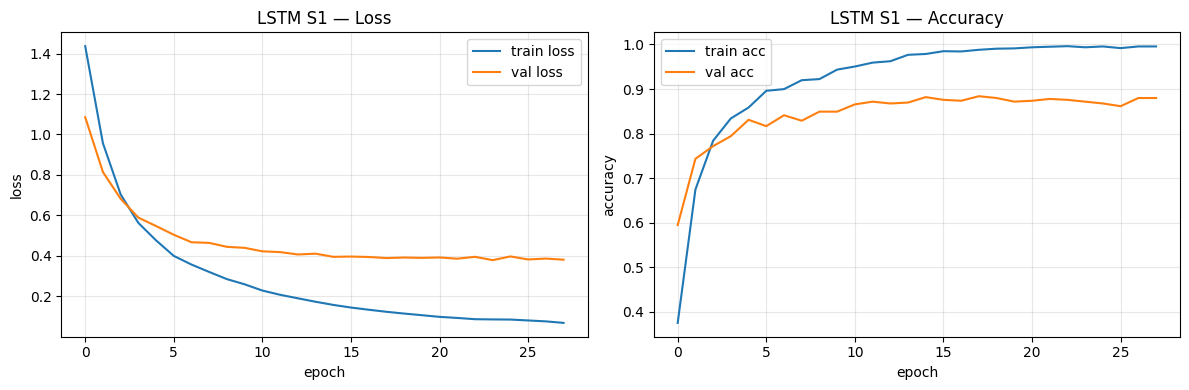

In [20]:
# Cell — Scenario 1: LSTM learning curve (Rule 6)
LSTM_LC_S1 = os.path.join(WORK_DIR, "lstm_s1_learning_curve.png")
plot_learning_curve(hist_lstm_s1, "LSTM S1", LSTM_LC_S1)

In [21]:
# Cell — Scenario 1: reload best LSTM + get probabilities (Rule 10)
best_lstm_s1 = tf.keras.models.load_model(ckpt_lstm_s1)
lstm_probs_train_s1 = best_lstm_s1.predict(feat_train_s1_lstm, batch_size=BATCH_SIZE, verbose=0)
lstm_probs_test_s1  = best_lstm_s1.predict(feat_test_s1_lstm,  batch_size=BATCH_SIZE, verbose=0)
print("LSTM probs:", lstm_probs_train_s1.shape, lstm_probs_test_s1.shape)

LSTM probs: (1597, 5) (373, 5)


In [22]:
# Cell — Scenario 1: build meta-features [P_Mixer | P_LSTM]
X_meta_train_s1 = np.concatenate([mixer_probs_train_s1, lstm_probs_train_s1], axis=1)
X_meta_test_s1  = np.concatenate([mixer_probs_test_s1,  lstm_probs_test_s1],  axis=1)
nan_s1 = np.isnan(X_meta_train_s1).sum()
if nan_s1 > 0:
    print(f"WARNING: {nan_s1} NaN in S1 meta-features (model diverged) — replacing with 0")
    X_meta_train_s1 = np.nan_to_num(X_meta_train_s1, nan=0.0)
    X_meta_test_s1  = np.nan_to_num(X_meta_test_s1,  nan=0.0)
print("Meta-features S1:", X_meta_train_s1.shape, X_meta_test_s1.shape,
      "| expected cols:", 2 * num_classes)

Meta-features S1: (1597, 10) (373, 10) | expected cols: 10


In [23]:
# Cell — Scenario 1: train SVM (Level 2) via GridSearchCV
param_grid = {
    "C": [0.1, 1, 2, 10, 100],
    "gamma": [1, 0.1, 0.01, 0.001, 0.0001],
    "kernel": ["linear", "rbf"],
}
svm_base_s1 = SVC(probability=False, class_weight=SVM_CLASS_WEIGHT, random_state=SEED)
grid_s1 = GridSearchCV(svm_base_s1, param_grid, cv=5,
                          scoring="accuracy", n_jobs=-1, verbose=1)
grid_s1.fit(X_meta_train_s1, y_train_s1)
best_svm_s1 = grid_s1.best_estimator_
print("Best SVM params:", grid_s1.best_params_)
print("Best CV accuracy:", round(grid_s1.best_score_, 4))
joblib.dump(best_svm_s1, os.path.join(WORK_DIR, "best_svm_s1.pkl"))

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best SVM params: {'C': 1, 'gamma': 1, 'kernel': 'rbf'}
Best CV accuracy: 0.9912


['/kaggle/working/best_svm_s1.pkl']

In [24]:
# Cell — Scenario 1: final ensemble evaluation on TEST set (Rule 4)
y_pred_s1 = best_svm_s1.predict(X_meta_test_s1)
metrics_s1 = report_metrics(y_test, y_pred_s1, class_names, "Scenario 1 (Baseline)")

=== Scenario 1 (Baseline) ===
Accuracy      : 0.8874
F1-score(macro): 0.8910
Recall(macro) : 0.8930

                     precision    recall  f1-score   support

        anthracnose     1.0000    1.0000    1.0000        62
            healthy     0.8333    0.8974    0.8642        78
          leaf_curl     0.8571    0.9730    0.9114        74
          leaf_spot     0.8169    0.7632    0.7891        76
nutrient_deficiency     0.9583    0.8313    0.8903        83

           accuracy                         0.8874       373
          macro avg     0.8931    0.8930    0.8910       373
       weighted avg     0.8902    0.8874    0.8866       373



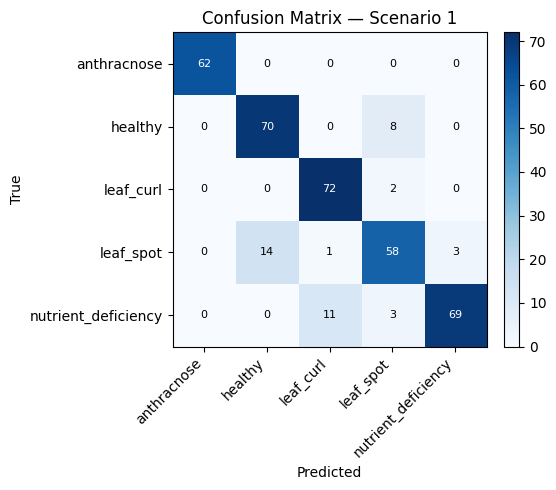

In [25]:
# Cell — Scenario 1: confusion matrix (Rule 6)
CM_S1 = os.path.join(WORK_DIR, "confusion_matrix_s1.png")
plot_confusion_matrix(y_test, y_pred_s1, class_names,
                      "Confusion Matrix — Scenario 1", CM_S1)

In [26]:
# Cell — Scenario 1: parameter counts + metrics bundle for export
total_params_s1 = mixer_params_s1 + lstm_params_s1
print(f"MLP-Mixer params : {mixer_params_s1:,}")
print(f"LSTM params      : {lstm_params_s1:,}")
print(f"Level-1 total    : {total_params_s1:,}  (SVM params not parametric)")

baseline_metrics = {
    "model_name": "Meta-Ensemble (MLP-Mixer + LSTM + SVM)",
    "accuracy": metrics_s1["accuracy"],
    "f1_macro": metrics_s1["f1_macro"],
    "recall_macro": metrics_s1["recall_macro"],
    "total_params": int(total_params_s1),
}
BASELINE_LEARNING_CURVE_PATH = MIXER_LC_S1  # representative LC (Mixer)
BASELINE_CONFUSION_MATRIX_PATH = CM_S1
print("\\nMetrics bundle ready for Excel export.")

MLP-Mixer params : 572,923
LSTM params      : 679,715
Level-1 total    : 1,252,638  (SVM params not parametric)
\nMetrics bundle ready for Excel export.


In [27]:
# Cell — Clear GPU memory before Scenario 2 (Rule 13)
import gc as _gc
tf.keras.backend.clear_session()
_gc.collect()
print("Cleared Keras session + ran gc before Scenario 2.")

# Keras 3 clear_session() resets weights of model objects held in Python variables.
# Rebuild _feature_nets so S2 CNN feature extraction uses correct ImageNet weights.
_feature_nets = build_feature_extractors()
print("CNN feature extractors rebuilt with ImageNet weights.")

Cleared Keras session + ran gc before Scenario 2.


/tmp/ipykernel_58/2158581383.py:8: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  "MobileNet":   MobileNet(**common),


CNN feature extractors rebuilt with ImageNet weights.


# Scenario 2 — Augmented

Training transform adds the 4 mandated augmentations (Rotation, Zoom, Horizontal
Flip, Brightness). Test set stays baseline. Fresh model weights throughout.

In [28]:
# Cell — Scenario 2 training data (AUGMENTED)
# 4 augmentations (Rule 3): Rotation, Zoom/Scale, Horizontal Flip, Brightness.
# Test set is NEVER augmented.
aug_gen = ImageDataGenerator(
    rotation_range=30,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.7, 1.3],
    fill_mode="nearest",
)

# Materialize one augmented copy per training image, then concat with originals.
# (Offline expansion so CNN feature extraction + LSTM see augmented data once.)
rng = np.random.RandomState(SEED)
aug_imgs = np.empty_like(X_train)
for i in range(len(X_train)):
    aug_imgs[i] = aug_gen.random_transform(X_train[i], seed=int(rng.randint(0, 1_000_000)))
aug_imgs = np.clip(aug_imgs, 0.0, 1.0).astype(np.float32)

X_train_s2 = np.concatenate([X_train, aug_imgs], axis=0)
y_train_s2 = np.concatenate([y_train, y_train], axis=0)

# shuffle
perm = rng.permutation(len(X_train_s2))
X_train_s2 = X_train_s2[perm]
y_train_s2 = y_train_s2[perm]
print("Scenario 2 augmented train set:", X_train_s2.shape)

Scenario 2 augmented train set: (3194, 64, 64, 3)


In [29]:
# Cell — Scenario 2 class weights (recomputed for this train set)
_counts_s2 = np.bincount(y_train_s2, minlength=num_classes)
_ratio_s2 = _counts_s2.max() / max(_counts_s2.min(), 1)
if _ratio_s2 >= 1.5:
    _cw_s2 = compute_class_weight("balanced", classes=np.arange(num_classes), y=y_train_s2)
    class_weight_s2 = {i: float(w) for i, w in enumerate(_cw_s2)}
    print("Scenario 2: class weighting ON ->", class_weight_s2)
else:
    class_weight_s2 = None
    print("Scenario 2: class weighting OFF (ratio {:.2f})".format(_ratio_s2))

Scenario 2: class weighting OFF (ratio 1.34)


In [30]:
# Cell — Scenario 2: build MLP-Mixer + print summary (Rule 5)
mixer_s2 = build_mixer(num_classes)
mixer_s2.compile(
    optimizer=Adam(LR, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
mixer_s2.summary()
mixer_params_s2 = mixer_s2.count_params()
print(f"MLP-Mixer S2 params: {mixer_params_s2:,}")

Model: "MLP_Mixer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resize_72           │ (None, 72, 72, 3) │          0 │ input_layer_4[0]… │
│ (Resizing)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patchify (Reshape)  │ (None, 9, 1728)   │          0 │ resize_72[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_proj (Dense)  │ (None, 9, 128)    │    221,312 │ patchify[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 9, 128)    │          0 │ patch_proj[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_fc1_0 (Dense)   │ (None, 9, 128)    │     16,512 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_T1_0 (Permute)  │ (None, 128, 9)    │          0 │ tok_fc1_0[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_fc2_0 (Dense)   │ (None, 128, 9)    │         90 │ tok_T1_0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_T2_0 (Permute)  │ (None, 9, 128)    │          0 │ tok_fc2_0[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_add_0 (Add)     │ (None, 9, 128)    │          0 │ dropout[0][0],    │
│                     │                   │            │ tok_T2_0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_ln_0            │ (None, 9, 128)    │        256 │ tok_add_0[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ch_fc1_0 (Dense)    │ (None, 9, 128)    │     16,512 │ tok_ln_0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ch_fc2_0 (Dense)    │ (None, 9, 128)    │     16,512 │ ch_fc1_0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ch_add_0 (Add)      │ (None, 9, 128)    │          0 │ tok_ln_0[0][0],   │
│                     │                   │            │ ch_fc2_0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ch_ln_0             │ (None, 9, 128)    │        256 │ ch_add_0[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_fc1_1 (Dense)   │ (None, 9, 128)    │     16,512 │ ch_ln_0[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_T1_1 (Permute)  │ (None, 128, 9)    │          0 │ tok_fc1_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_fc2_1 (Dense)   │ (None, 128, 9)    │         90 │ tok_T1_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_T2_1 (Permute)  │ (None, 9, 128)    │          0 │ tok_fc2_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_add_1 (Add)     │ (None, 9, 128)    │          0 │ ch_ln_0[0][0],    │
│                     │                   │            │ tok_T2_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tok_ln_1            │ (None, 9, 128)    │        256 │ tok_add_1[0][0]   │
│ (LayerNormalizatio… │                   │            │                 

 Total params: 572,923 (2.19 MB)

 Trainable params: 572,923 (2.19 MB)

 Non-trainable params: 0 (0.00 B)

MLP-Mixer S2 params: 572,923


In [31]:
# Cell — Scenario 2: train MLP-Mixer
ckpt_mixer_s2 = os.path.join(WORK_DIR, "best_mixer_s2.keras")
cb_mixer_s2 = [
    ModelCheckpoint(ckpt_mixer_s2, monitor="val_accuracy",
                    save_best_only=True, mode="max"),
    EarlyStopping(monitor="val_accuracy", patience=PATIENCE,
                  restore_best_weights=True, mode="max"),
    tf.keras.callbacks.TerminateOnNaN(),
]
train_ds_mixer_s2 = make_tf_dataset(X_train_s2, y_train_s2, BATCH_SIZE, shuffle=True)
val_ds_mixer      = make_tf_dataset(X_val, y_val, BATCH_SIZE)
hist_mixer_s2 = mixer_s2.fit(
    train_ds_mixer_s2,
    validation_data=val_ds_mixer,
    epochs=EPOCHS,
    class_weight=class_weight_s2,
    callbacks=cb_mixer_s2, verbose=2,
)
print("Mixer S2 training done.")

Epoch 1/100
7/7 - 37s - 5s/step - accuracy: 0.2023 - loss: 1.9641 - val_accuracy: 0.1996 - val_loss: 1.7073
Epoch 2/100
7/7 - 1s - 85ms/step - accuracy: 0.2007 - loss: 1.6903 - val_accuracy: 0.3299 - val_loss: 1.6181
Epoch 3/100
7/7 - 0s - 37ms/step - accuracy: 0.2295 - loss: 1.6297 - val_accuracy: 0.2729 - val_loss: 1.5664
Epoch 4/100
7/7 - 1s - 79ms/step - accuracy: 0.2179 - loss: 1.6292 - val_accuracy: 0.3686 - val_loss: 1.5010
Epoch 5/100
7/7 - 0s - 35ms/step - accuracy: 0.2395 - loss: 1.6031 - val_accuracy: 0.3422 - val_loss: 1.4326
Epoch 6/100
7/7 - 1s - 84ms/step - accuracy: 0.2808 - loss: 1.5356 - val_accuracy: 0.4134 - val_loss: 1.3287
Epoch 7/100
7/7 - 0s - 34ms/step - accuracy: 0.2924 - loss: 1.4921 - val_accuracy: 0.3809 - val_loss: 1.3141
Epoch 8/100
7/7 - 0s - 35ms/step - accuracy: 0.2968 - loss: 1.4973 - val_accuracy: 0.4073 - val_loss: 1.2551
Epoch 9/100
7/7 - 1s - 80ms/step - accuracy: 0.2977 - loss: 1.4752 - val_accuracy: 0.4399 - val_loss: 1.2310
Epoch 10/100
7/7 - 1

In [ ]:
# Cell — Scenario 2: MLP-Mixer learning curve (Rule 6)
MIXER_LC_S2 = os.path.join(WORK_DIR, "mixer_s2_learning_curve.png")
plot_learning_curve(hist_mixer_s2, "Mixer S2", MIXER_LC_S2)

In [33]:
# Cell — Scenario 2: reload best Mixer + get probabilities (Rule 10)
best_mixer_s2 = tf.keras.models.load_model(ckpt_mixer_s2)
mixer_probs_train_s2 = best_mixer_s2.predict(X_train_s2, batch_size=BATCH_SIZE, verbose=0)
mixer_probs_test_s2  = best_mixer_s2.predict(X_test,        batch_size=BATCH_SIZE, verbose=0)
print("Mixer probs:", mixer_probs_train_s2.shape, mixer_probs_test_s2.shape)

Mixer probs: (3194, 5) (373, 5)


In [34]:
# Cell — Scenario 2: extract CNN features (train uses augmented images)
feat_train_s2 = extract_cnn_features(X_train_s2)
feat_test_s2  = extract_cnn_features(X_test)
FEATURE_DIM = feat_train_s2.shape[1]   # auto-detect (expected 5632)
print("CNN features:", feat_train_s2.shape, feat_test_s2.shape, "| FEATURE_DIM =", FEATURE_DIM)

# reshape for LSTM: (N, timestep=1, FEATURE_DIM)
feat_train_s2_lstm = feat_train_s2.reshape(-1, 1, FEATURE_DIM)
feat_test_s2_lstm  = feat_test_s2.reshape(-1, 1, FEATURE_DIM)

2026-06-20 04:52:57.547838: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-20 04:52:57.696024: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


CNN features: (3194, 5632) (373, 5632) | FEATURE_DIM = 5632


In [35]:
# Cell — Scenario 2: build LSTM + print summary (Rule 5)
lstm_s2 = build_lstm(num_classes, FEATURE_DIM)
lstm_s2.compile(
    optimizer=Adam(LR, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
lstm_s2.summary()
lstm_params_s2 = lstm_s2.count_params()
print(f"LSTM S2 params: {lstm_params_s2:,}")

Model: "LSTM_branch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 1, 5632)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30)             │       679,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_out (Dense)                │ (None, 5)              │           155 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 679,715 (2.59 MB)

 Trainable params: 679,715 (2.59 MB)

 Non-trainable params: 0 (0.00 B)

LSTM S2 params: 679,715


In [36]:
# Cell — Scenario 2: train LSTM on cached features
ckpt_lstm_s2 = os.path.join(WORK_DIR, "best_lstm_s2.keras")
cb_lstm_s2 = [
    ModelCheckpoint(ckpt_lstm_s2, monitor="val_accuracy",
                    save_best_only=True, mode="max"),
    EarlyStopping(monitor="val_accuracy", patience=PATIENCE,
                  restore_best_weights=True, mode="max"),
    tf.keras.callbacks.TerminateOnNaN(),
]
train_ds_lstm_s2 = make_tf_dataset(feat_train_s2_lstm, y_train_s2, BATCH_SIZE, shuffle=True)
val_ds_lstm      = make_tf_dataset(feat_val_lstm, y_val, BATCH_SIZE)
hist_lstm_s2 = lstm_s2.fit(
    train_ds_lstm_s2,
    validation_data=val_ds_lstm,
    epochs=EPOCHS,
    class_weight=class_weight_s2,
    callbacks=cb_lstm_s2, verbose=2,
)
print("LSTM S2 training done.")

Epoch 1/100
7/7 - 2s - 216ms/step - accuracy: 0.3441 - loss: 1.4771 - val_accuracy: 0.6741 - val_loss: 0.9563
Epoch 2/100
7/7 - 0s - 20ms/step - accuracy: 0.4915 - loss: 1.1989 - val_accuracy: 0.7515 - val_loss: 0.6984
Epoch 3/100
7/7 - 0s - 19ms/step - accuracy: 0.5238 - loss: 1.0907 - val_accuracy: 0.8248 - val_loss: 0.5445
Epoch 4/100
7/7 - 0s - 19ms/step - accuracy: 0.5529 - loss: 1.0215 - val_accuracy: 0.8330 - val_loss: 0.4974
Epoch 5/100
7/7 - 0s - 19ms/step - accuracy: 0.5645 - loss: 0.9798 - val_accuracy: 0.8473 - val_loss: 0.4517
Epoch 6/100
7/7 - 0s - 19ms/step - accuracy: 0.5623 - loss: 0.9524 - val_accuracy: 0.8697 - val_loss: 0.4097
Epoch 7/100
7/7 - 0s - 13ms/step - accuracy: 0.5874 - loss: 0.9258 - val_accuracy: 0.8635 - val_loss: 0.4139
Epoch 8/100
7/7 - 0s - 12ms/step - accuracy: 0.5911 - loss: 0.9090 - val_accuracy: 0.8574 - val_loss: 0.4068
Epoch 9/100
7/7 - 0s - 18ms/step - accuracy: 0.5855 - loss: 0.8931 - val_accuracy: 0.8717 - val_loss: 0.3890
Epoch 10/100
7/7 -

In [37]:
# Cell — Scenario 2: reload best LSTM + get probabilities (Rule 10)
best_lstm_s2 = tf.keras.models.load_model(ckpt_lstm_s2)
lstm_probs_train_s2 = best_lstm_s2.predict(feat_train_s2_lstm, batch_size=BATCH_SIZE, verbose=0)
lstm_probs_test_s2  = best_lstm_s2.predict(feat_test_s2_lstm,  batch_size=BATCH_SIZE, verbose=0)
print("LSTM S2 probs:", lstm_probs_train_s2.shape, lstm_probs_test_s2.shape)

LSTM S2 probs: (3194, 5) (373, 5)


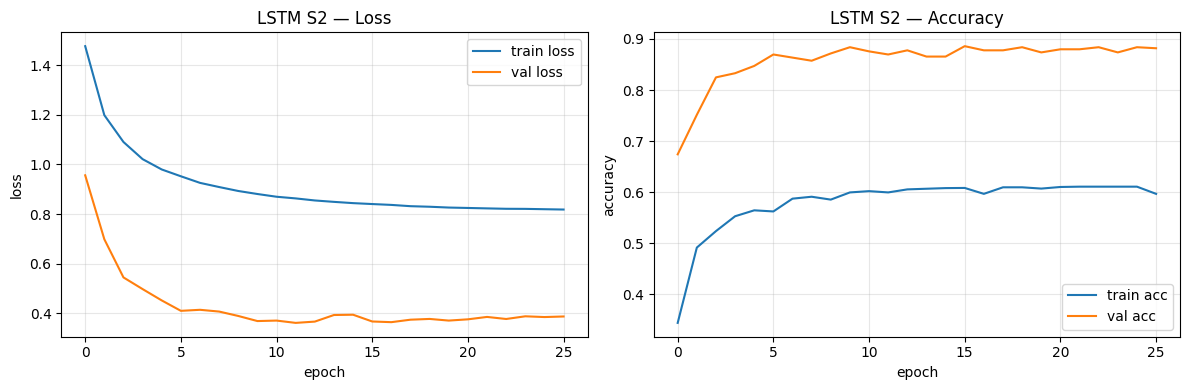

In [38]:
# Cell — Scenario 2: LSTM learning curve (Rule 6)
LSTM_LC_S2 = os.path.join(WORK_DIR, "lstm_s2_learning_curve.png")
plot_learning_curve(hist_lstm_s2, "LSTM S2", LSTM_LC_S2)

In [39]:
# Cell — Scenario 2: build meta-features [P_Mixer | P_LSTM]
X_meta_train_s2 = np.concatenate([mixer_probs_train_s2, lstm_probs_train_s2], axis=1)
X_meta_test_s2  = np.concatenate([mixer_probs_test_s2,  lstm_probs_test_s2],  axis=1)
nan_s2 = np.isnan(X_meta_train_s2).sum()
if nan_s2 > 0:
    print(f"WARNING: {nan_s2} NaN in S2 meta-features (model diverged) — replacing with 0")
    X_meta_train_s2 = np.nan_to_num(X_meta_train_s2, nan=0.0)
    X_meta_test_s2  = np.nan_to_num(X_meta_test_s2,  nan=0.0)
print("Meta-features S2:", X_meta_train_s2.shape, X_meta_test_s2.shape,
      "| expected cols:", 2 * num_classes)

Meta-features S2: (3194, 10) (373, 10) | expected cols: 10


In [40]:
# Cell — Scenario 2: train SVM (Level 2) via GridSearchCV
param_grid = {
    "C": [0.1, 1, 2, 10, 100],
    "gamma": [1, 0.1, 0.01, 0.001, 0.0001],
    "kernel": ["linear", "rbf"],
}
svm_base_s2 = SVC(probability=False, class_weight=SVM_CLASS_WEIGHT, random_state=SEED)
grid_s2 = GridSearchCV(svm_base_s2, param_grid, cv=5,
                          scoring="accuracy", n_jobs=-1, verbose=1)
grid_s2.fit(X_meta_train_s2, y_train_s2)
best_svm_s2 = grid_s2.best_estimator_
print("Best SVM params:", grid_s2.best_params_)
print("Best CV accuracy:", round(grid_s2.best_score_, 4))
joblib.dump(best_svm_s2, os.path.join(WORK_DIR, "best_svm_s2.pkl"))

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best SVM params: {'C': 0.1, 'gamma': 1, 'kernel': 'linear'}
Best CV accuracy: 0.6102


['/kaggle/working/best_svm_s2.pkl']

In [41]:
# Cell — Scenario 2: final ensemble evaluation on TEST set (Rule 4)
y_pred_s2 = best_svm_s2.predict(X_meta_test_s2)
metrics_s2 = report_metrics(y_test, y_pred_s2, class_names, "Scenario 2 (Augmented)")

=== Scenario 2 (Augmented) ===
Accuracy      : 0.8874
F1-score(macro): 0.8907
Recall(macro) : 0.8930

                     precision    recall  f1-score   support

        anthracnose     1.0000    1.0000    1.0000        62
            healthy     0.8675    0.9231    0.8944        78
          leaf_curl     0.8256    0.9595    0.8875        74
          leaf_spot     0.8529    0.7632    0.8056        76
nutrient_deficiency     0.9189    0.8193    0.8662        83

           accuracy                         0.8874       373
          macro avg     0.8930    0.8930    0.8907       373
       weighted avg     0.8897    0.8874    0.8862       373



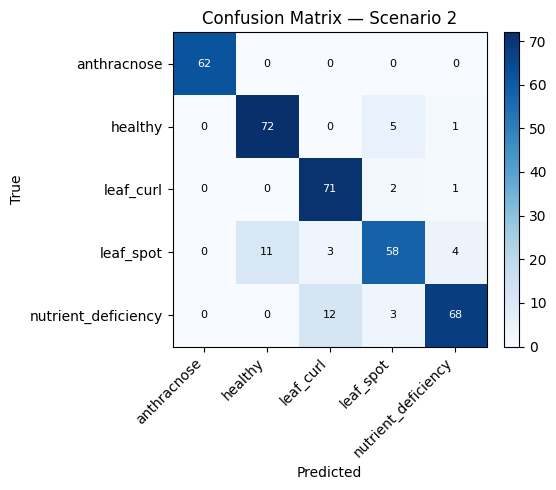

In [42]:
# Cell — Scenario 2: confusion matrix (Rule 6)
CM_S2 = os.path.join(WORK_DIR, "confusion_matrix_s2.png")
plot_confusion_matrix(y_test, y_pred_s2, class_names,
                      "Confusion Matrix — Scenario 2", CM_S2)

In [43]:
# Cell — Scenario 2: parameter counts + metrics bundle for export
total_params_s2 = mixer_params_s2 + lstm_params_s2
print(f"MLP-Mixer params : {mixer_params_s2:,}")
print(f"LSTM params      : {lstm_params_s2:,}")
print(f"Level-1 total    : {total_params_s2:,}  (SVM params not parametric)")

aug_metrics = {
    "model_name": "Meta-Ensemble (MLP-Mixer + LSTM + SVM)",
    "accuracy": metrics_s2["accuracy"],
    "f1_macro": metrics_s2["f1_macro"],
    "recall_macro": metrics_s2["recall_macro"],
    "total_params": int(total_params_s2),
}
AUG_LEARNING_CURVE_PATH = MIXER_LC_S2  # representative LC (Mixer)
AUG_CONFUSION_MATRIX_PATH = CM_S2
print("\\nMetrics bundle ready for Excel export.")

MLP-Mixer params : 572,923
LSTM params      : 679,715
Level-1 total    : 1,252,638  (SVM params not parametric)


NameError: name 'MIXER_LC_S2' is not defined

## Scenario 1 vs Scenario 2 — Summary

In [ ]:
# Cell — Side-by-side comparison
import pandas as pd
cmp = pd.DataFrame([
    {"Scenario": "Baseline (No-Aug)",
     "Accuracy": baseline_metrics["accuracy"],
     "F1-macro": baseline_metrics["f1_macro"],
     "Recall-macro": baseline_metrics["recall_macro"],
     "Params": baseline_metrics["total_params"]},
    {"Scenario": "Augmented",
     "Accuracy": aug_metrics["accuracy"],
     "F1-macro": aug_metrics["f1_macro"],
     "Recall-macro": aug_metrics["recall_macro"],
     "Params": aug_metrics["total_params"]},
])
print(cmp.to_string(index=False))

## Excel Export — results_summary.xlsx

In [ ]:
# Cell — Export results_summary.xlsx (two sheets: Baseline, Augmented)
import openpyxl
from openpyxl import Workbook
from openpyxl.styles import Font, Alignment, PatternFill, Border, Side
from openpyxl.drawing.image import Image as XLImage
from openpyxl.utils import get_column_letter

EXCEL_OUTPUT_PATH = os.path.join(WORK_DIR, "results_summary.xlsx")

HEADERS = ["STT", "TÃªn Model", "Accuracy", "F1-score", "Recall",
           "Learning Curve", "Confusion Matrix", "Parameters"]
COL_WIDTHS = [6, 35, 12, 12, 12, 38, 38, 18]
IMG_ROW_HEIGHT = 200


def style_header_row(ws):
    fill = PatternFill("solid", fgColor="1F4E79")
    font = Font(bold=True, color="FFFFFF", size=11)
    border = Border(bottom=Side(style="medium", color="FFFFFF"),
                    right=Side(style="thin", color="FFFFFF"))
    for col, header in enumerate(HEADERS, start=1):
        cell = ws.cell(row=1, column=col, value=header)
        cell.fill, cell.font, cell.border = fill, font, border
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)


def write_result_row(ws, row_num, stt, metrics, lc_path, cm_path):
    data = [stt, metrics["model_name"], round(metrics["accuracy"], 4),
            round(metrics["f1_macro"], 4), round(metrics["recall_macro"], 4),
            "", "", f"{metrics['total_params']:,}"]
    for col, val in enumerate(data, start=1):
        cell = ws.cell(row=row_num, column=col, value=val)
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    ws.row_dimensions[row_num].height = IMG_ROW_HEIGHT
    if os.path.exists(lc_path):
        img_lc = XLImage(lc_path); img_lc.width, img_lc.height = 280, 190
        ws.add_image(img_lc, f"F{row_num}")
    if os.path.exists(cm_path):
        img_cm = XLImage(cm_path); img_cm.width, img_cm.height = 280, 190
        ws.add_image(img_cm, f"G{row_num}")


def build_sheet(wb, sheet_name, metrics, lc_path, cm_path):
    ws = wb.create_sheet(title=sheet_name)
    for col, width in enumerate(COL_WIDTHS, start=1):
        ws.column_dimensions[get_column_letter(col)].width = width
    ws.row_dimensions[1].height = 30
    style_header_row(ws)
    write_result_row(ws, 2, 1, metrics, lc_path, cm_path)
    return ws


wb = Workbook(); wb.remove(wb.active)
build_sheet(wb, "Baseline", baseline_metrics,
            BASELINE_LEARNING_CURVE_PATH, BASELINE_CONFUSION_MATRIX_PATH)
build_sheet(wb, "Augmented", aug_metrics,
            AUG_LEARNING_CURVE_PATH, AUG_CONFUSION_MATRIX_PATH)
wb.save(EXCEL_OUTPUT_PATH)
print(f"[Excel] saved -> {EXCEL_OUTPUT_PATH}")
print(f"  Baseline  -> Acc={baseline_metrics['accuracy']:.4f} F1={baseline_metrics['f1_macro']:.4f} Recall={baseline_metrics['recall_macro']:.4f} Params={baseline_metrics['total_params']:,}")
print(f"  Augmented -> Acc={aug_metrics['accuracy']:.4f} F1={aug_metrics['f1_macro']:.4f} Recall={aug_metrics['recall_macro']:.4f} Params={aug_metrics['total_params']:,}")